In [1]:
# Import packages
import sys
sys.path.append("./../")

import torch 
import os
import random

import numpy as np

from scripts.cshap import CustomDecomposition, EMDDecomposition, DWTDecomposition
from scripts.utils import load_model, load_array

In [2]:
# Set seeds
np.random.seed(10)
torch.manual_seed(10)
random.seed(10)

In [3]:
# Settings
dataset = 'opportunity_multi'         # Data set to calculate SHAP values for
exact = True                # If True calculate exact SHAP values, else use KernelSHAP
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu") # Device to load model and data to

In [4]:
# Select decomposition to use
decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'
max_imfs = 4            # Number of IMFs to include if EMD is used
noise_sigma = 1         # Used for the low_freq component if custom decomposition is used


In [5]:
# Input paths
data_path = './../data/prepared/' + dataset
model_path = './../models/' + dataset + '/multivariate/'

In [6]:
output_path = './data/cshap/' + dataset + '/multivariate/' + decomposition_def
output_path = output_path.replace('*', 'x')

In [7]:
class_dict = {0:'Stand', 1:'Walk', 2:'Sit', 3:'Lie'}
bidirectional = True
task = 'classification'
softmax = True
var_window_size = 27

In [8]:
# If output path does not yet exist, create it
if not os.path.exists(output_path):
    os.makedirs(output_path)
print('output path:', output_path)

output path: ./data/cshap/opportunity_multi/multivariate/trend+bias+scalex(low_freq+varxhigh_freq)


In [9]:
# Load data
X_train = load_array(data_path + '/X_train.pkl')
X_test = load_array(data_path +  '/X_test.pkl')

y_train = load_array(data_path +  '/y_train.pkl')
y_test = load_array(data_path +  '/y_test.pkl')

In [10]:
# Placeholder time steps
t = np.linspace(0, X_train.shape[1] + 1, X_train.shape[1])

In [11]:
from sklearn.model_selection import train_test_split

n_background = 100
def select_background_samples(n_background, X_train):
    _, select_indices = train_test_split(list(range(len(X_train))), test_size=n_background, stratify=y_train)
    return X_train[select_indices]

background_samples = select_background_samples(n_background, X_train)

In [12]:
# Instantiate the selected decomposition
if decomposition_def == 'EMD':
    decomposition = EMDDecomposition(max_imfs=max_imfs)
elif decomposition_def == 'DWT':
    decomposition = DWTDecomposition(level=3)
else:
    decomposition = CustomDecomposition(decomposition_def, noise_sigma=noise_sigma, 
                                        var_window_size=var_window_size)

In [13]:
model = load_model(model_path, task, bidirectional, X_train.shape[-1], class_dict, device, model_name='model.pt')

In [14]:
def encode_data_multi_variate(x, start_idx=0):
    n_components = x.shape[3] # Extract number of components
    n_variables = x.shape[2]

    # For each sample create one element in the array that refers to each component.
    # In the unshuffled encoded data (prior to SHAP)
    # each element should refer to the current index of the sample. When they indices get 
    # shuffled, they can be used to retrieve features from other samples.
    x_ = [[i]*n_components*n_variables for i in range(start_idx, start_idx + x.shape[0])]
    return np.array(x_)

In [15]:
# Decompose background data and put it in the correct shape
bg_components = np.zeros((background_samples.shape[0], background_samples.shape[1], 
                          background_samples.shape[2], len(decomposition.component_names)))

for i in range(background_samples.shape[2]):
    bg_components[:, :, i, :] = decomposition.decompose(t, background_samples[:, :, i][:, :, None])

# Encode background data into indices array of shape (# samples, # components) for SHAP purposes
bg_coded = encode_data_multi_variate(bg_components, start_idx=0)

In [16]:
# i_select = 256
i_select = 845

x_samples = X_test[i_select, :, :][None, :, :]

In [17]:
# Initialize array where to store the components extracted from the input data
x_components = np.zeros((x_samples.shape[0], x_samples.shape[1], x_samples.shape[2], len(decomposition.component_names)))

for i in range(x_samples.shape[2]):
    x_components[:, :, i, :] = decomposition.decompose(t, x_samples[:, :, i][:, :, None])

In [18]:
all_data = np.concatenate([bg_components, x_components], axis=0)

In [19]:
# Encode the input data, start encoding from index after background data, so they can be distinguished
x_coded = encode_data_multi_variate(x_components, start_idx=len(background_samples))

In [ ]:
from scripts.cshap.cshap_utils import TempDataset
from torch.utils.data import DataLoader

def shap_wrapper_multivariate(x_in, model, device,  batch_size=64):
    """
    Wrapper for the model predictions to give to SHAP. Takes encoded input data, to which SHAP has
    applied masking. The encoded input data contains per sample indices for each component. After SHAP's
    masking the index will either refer to the sample itself (features is not masked) or
    to the background sample from which to extract the feature (feature is masked).
    x_in: encoded data of shape (# masked samples to process, # components)
    model: PyTorch model to which to apply C-SHAP
    device: device the data should be located to (same as model)
    batch_size: to speed up parallel computing, the masked data is provided to the model in batches
    returns: the masked model input required by SHAP
    """

    x_coded = x_in.copy()       # For safety reasons copy data
    x_coded = x_coded.astype(int)   # Convert to integers

    # Determine number of components
    n_variables = all_data.shape[2]
    n_components = all_data.shape[3]

    # Used for storing the data 'reconstructed' from the masked encoded data
    x_c_reconstructed = np.zeros((x_coded.shape[0], all_data.shape[1], all_data.shape[2], n_components))

    # Extract data using the indices in the encoded data. Each index refers either to the original
    # sample or the background sample
    for v in range(n_variables):
        for c in range(n_components):
            background_indices = x_coded[:, v * n_components + c]
            x_c_reconstructed[:, :, v, c] = all_data[background_indices, :, v, c]

    # Compose the reconstructed components into input samples for the model
    x_input = np.zeros((x_in.shape[0], all_data.shape[1], n_variables))
    for v in range(n_variables):
        x_input[:, :, v] = decomposition.compose(x_c_reconstructed[:, :, v, :])

    # Create PyTorch tensor out of input samples
    input_tensor = torch.tensor(x_input, dtype=torch.float32, device=device)

    # Construct dataset and dataloader to supply samples to model
    dataset = TempDataset(input_tensor)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    # Put samples through model and store the outputs as list of numpy arrays
    model.eval()
    output_list = []
    for _, data in enumerate(dataloader):
        with torch.no_grad():
            data = data.to(device)
            if softmax:
                out = model(data, softmax=True).cpu().numpy()
            else:
                out = model(data).cpu().numpy()
            output_list.append(out)

    # Concatenate list of numpy arrays and we obtain the masked data in the format needed for SHAP
    output = np.concatenate(output_list, axis=0) 
    return output

In [21]:
import shap
explainer = shap.KernelExplainer(lambda x: shap_wrapper_multivariate(x, model, device), bg_coded)
complete_shap_values = explainer.shap_values(x_coded)
base_values = explainer.expected_value

  0%|          | 0/1 [00:00<?, ?it/s]

In [22]:
n_variables = X_test.shape[2]
n_components = len(decomposition.component_names)
shap_values = np.zeros((x_coded.shape[0], n_variables, len(decomposition.component_names), complete_shap_values.shape[-1]))

for i in range(complete_shap_values.shape[1]):
    v = int(i / n_components)
    c = i - v * n_components
    shap_values[:, v, c, :] = complete_shap_values[:, i, :]


In [23]:
class_select = y_test[i_select]
s_vals = shap_values[0, :, :, class_select]

In [24]:
# Take negative and positive data apart and cumulate
def get_cumulated_array(data, **kwargs):
    cum = data.clip(**kwargs)
    cum = np.cumsum(cum, axis=0)
    d = np.zeros(np.shape(data))
    d[1:] = cum[:-1]
    return d  

Text(0.5, 1.0, 'Explanation for Walk')

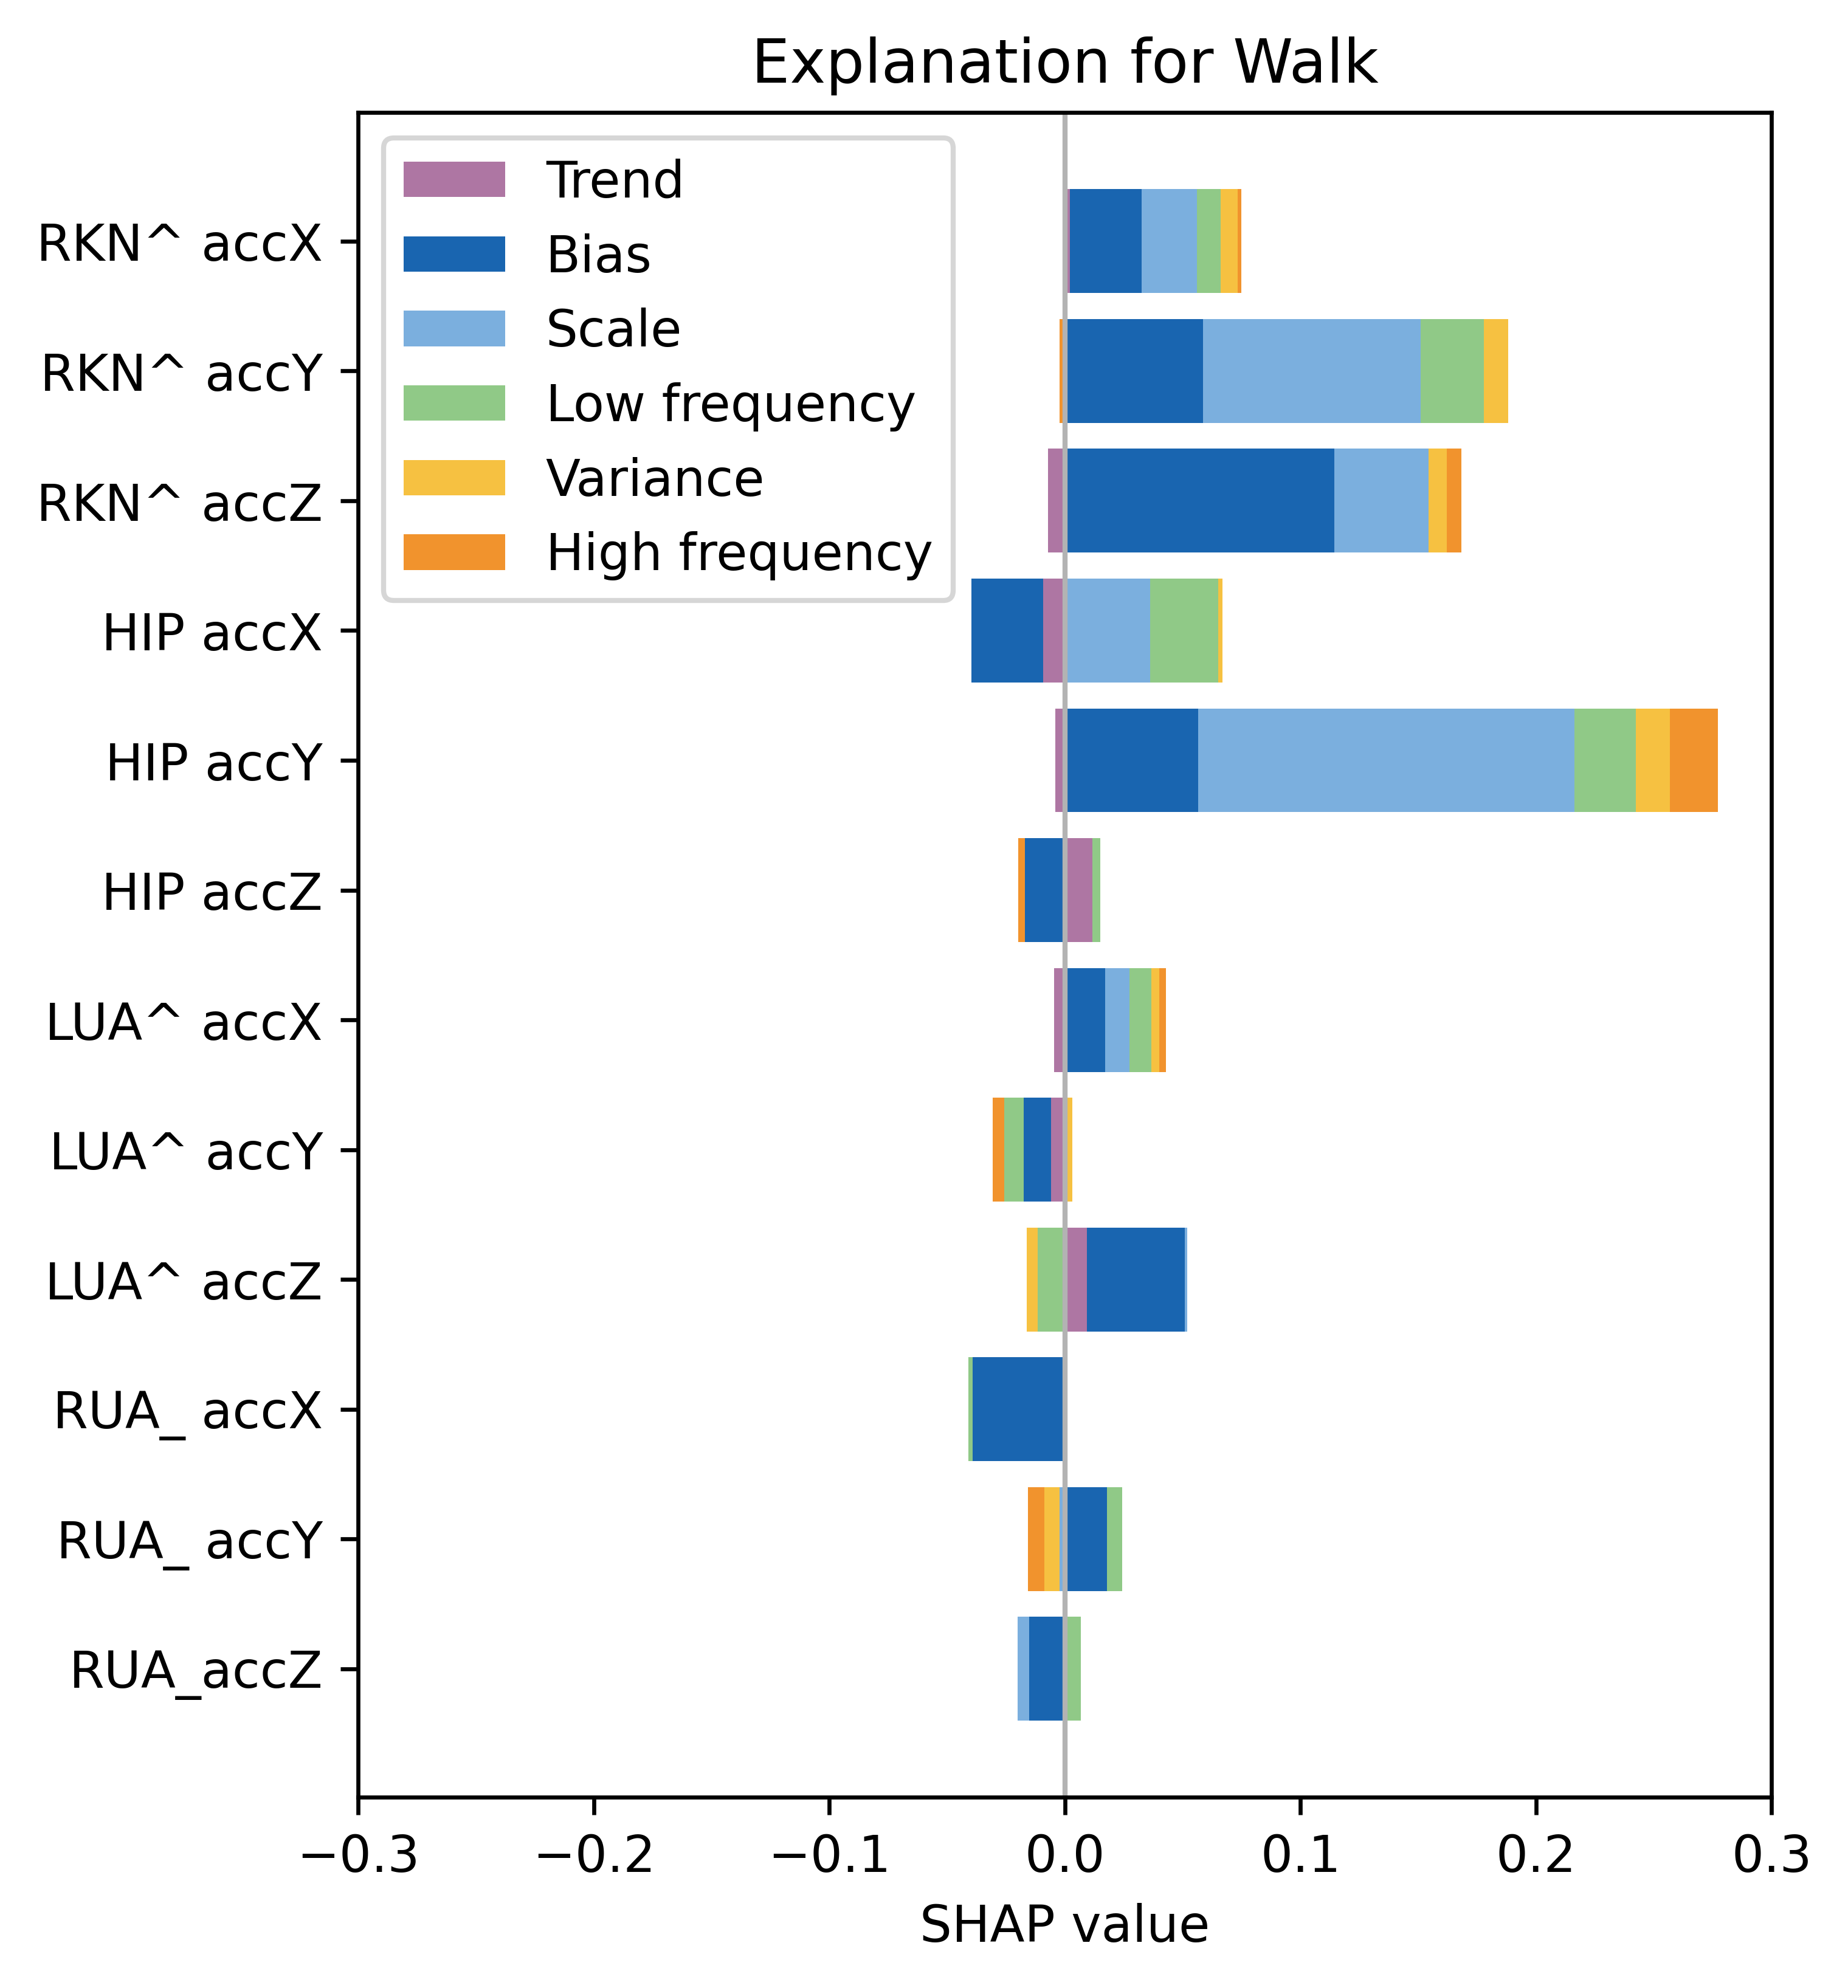

In [25]:
import matplotlib.pyplot as plt

cmap = ["#AE76A3", "#1965B0", "#7BAFDE", "#90C987", "#F6C141", "#F1932D", "#DC050C"]
n_features = s_vals.shape[0]
component_names = ['Trend', 'Bias', 'Scale', 'Low frequency', 'Variance', 'High frequency']
feature_names = ['RKN^ accX','RKN^ accY','RKN^ accZ','HIP accX','HIP accY','HIP accZ',
                'LUA^ accX','LUA^ accY','LUA^ accZ','RUA_ accX','RUA_ accY','RUA_accZ']

cumulated_data = get_cumulated_array(s_vals.T, min=0)
cumulated_data_neg = get_cumulated_array(s_vals.T, max=0)

# Re-merge negative and positive data.
row_mask = (s_vals.T<0)
cumulated_data[row_mask] = cumulated_data_neg[row_mask]
data_stack = cumulated_data

fig = plt.figure(dpi=600, figsize=(5, 6))
ax = plt.subplot(111)
for i in np.arange(0, n_components):
    ax.barh(list(reversed(range(n_features))), s_vals.T[i], left=data_stack[i], label=component_names[i], color=cmap[i])

# max_reach = np.max(np.sum(np.abs(s_vals.T), axis=1))
ax.axvline(x=0, color='#b3b3b3', linewidth=1)
plt.xlim(-0.3, 0.3)
plt.yticks(list(reversed(range(n_features))), feature_names)
plt.legend()
plt.xlabel('SHAP value');
plt.title('Explanation for ' + str(class_dict[class_select]))

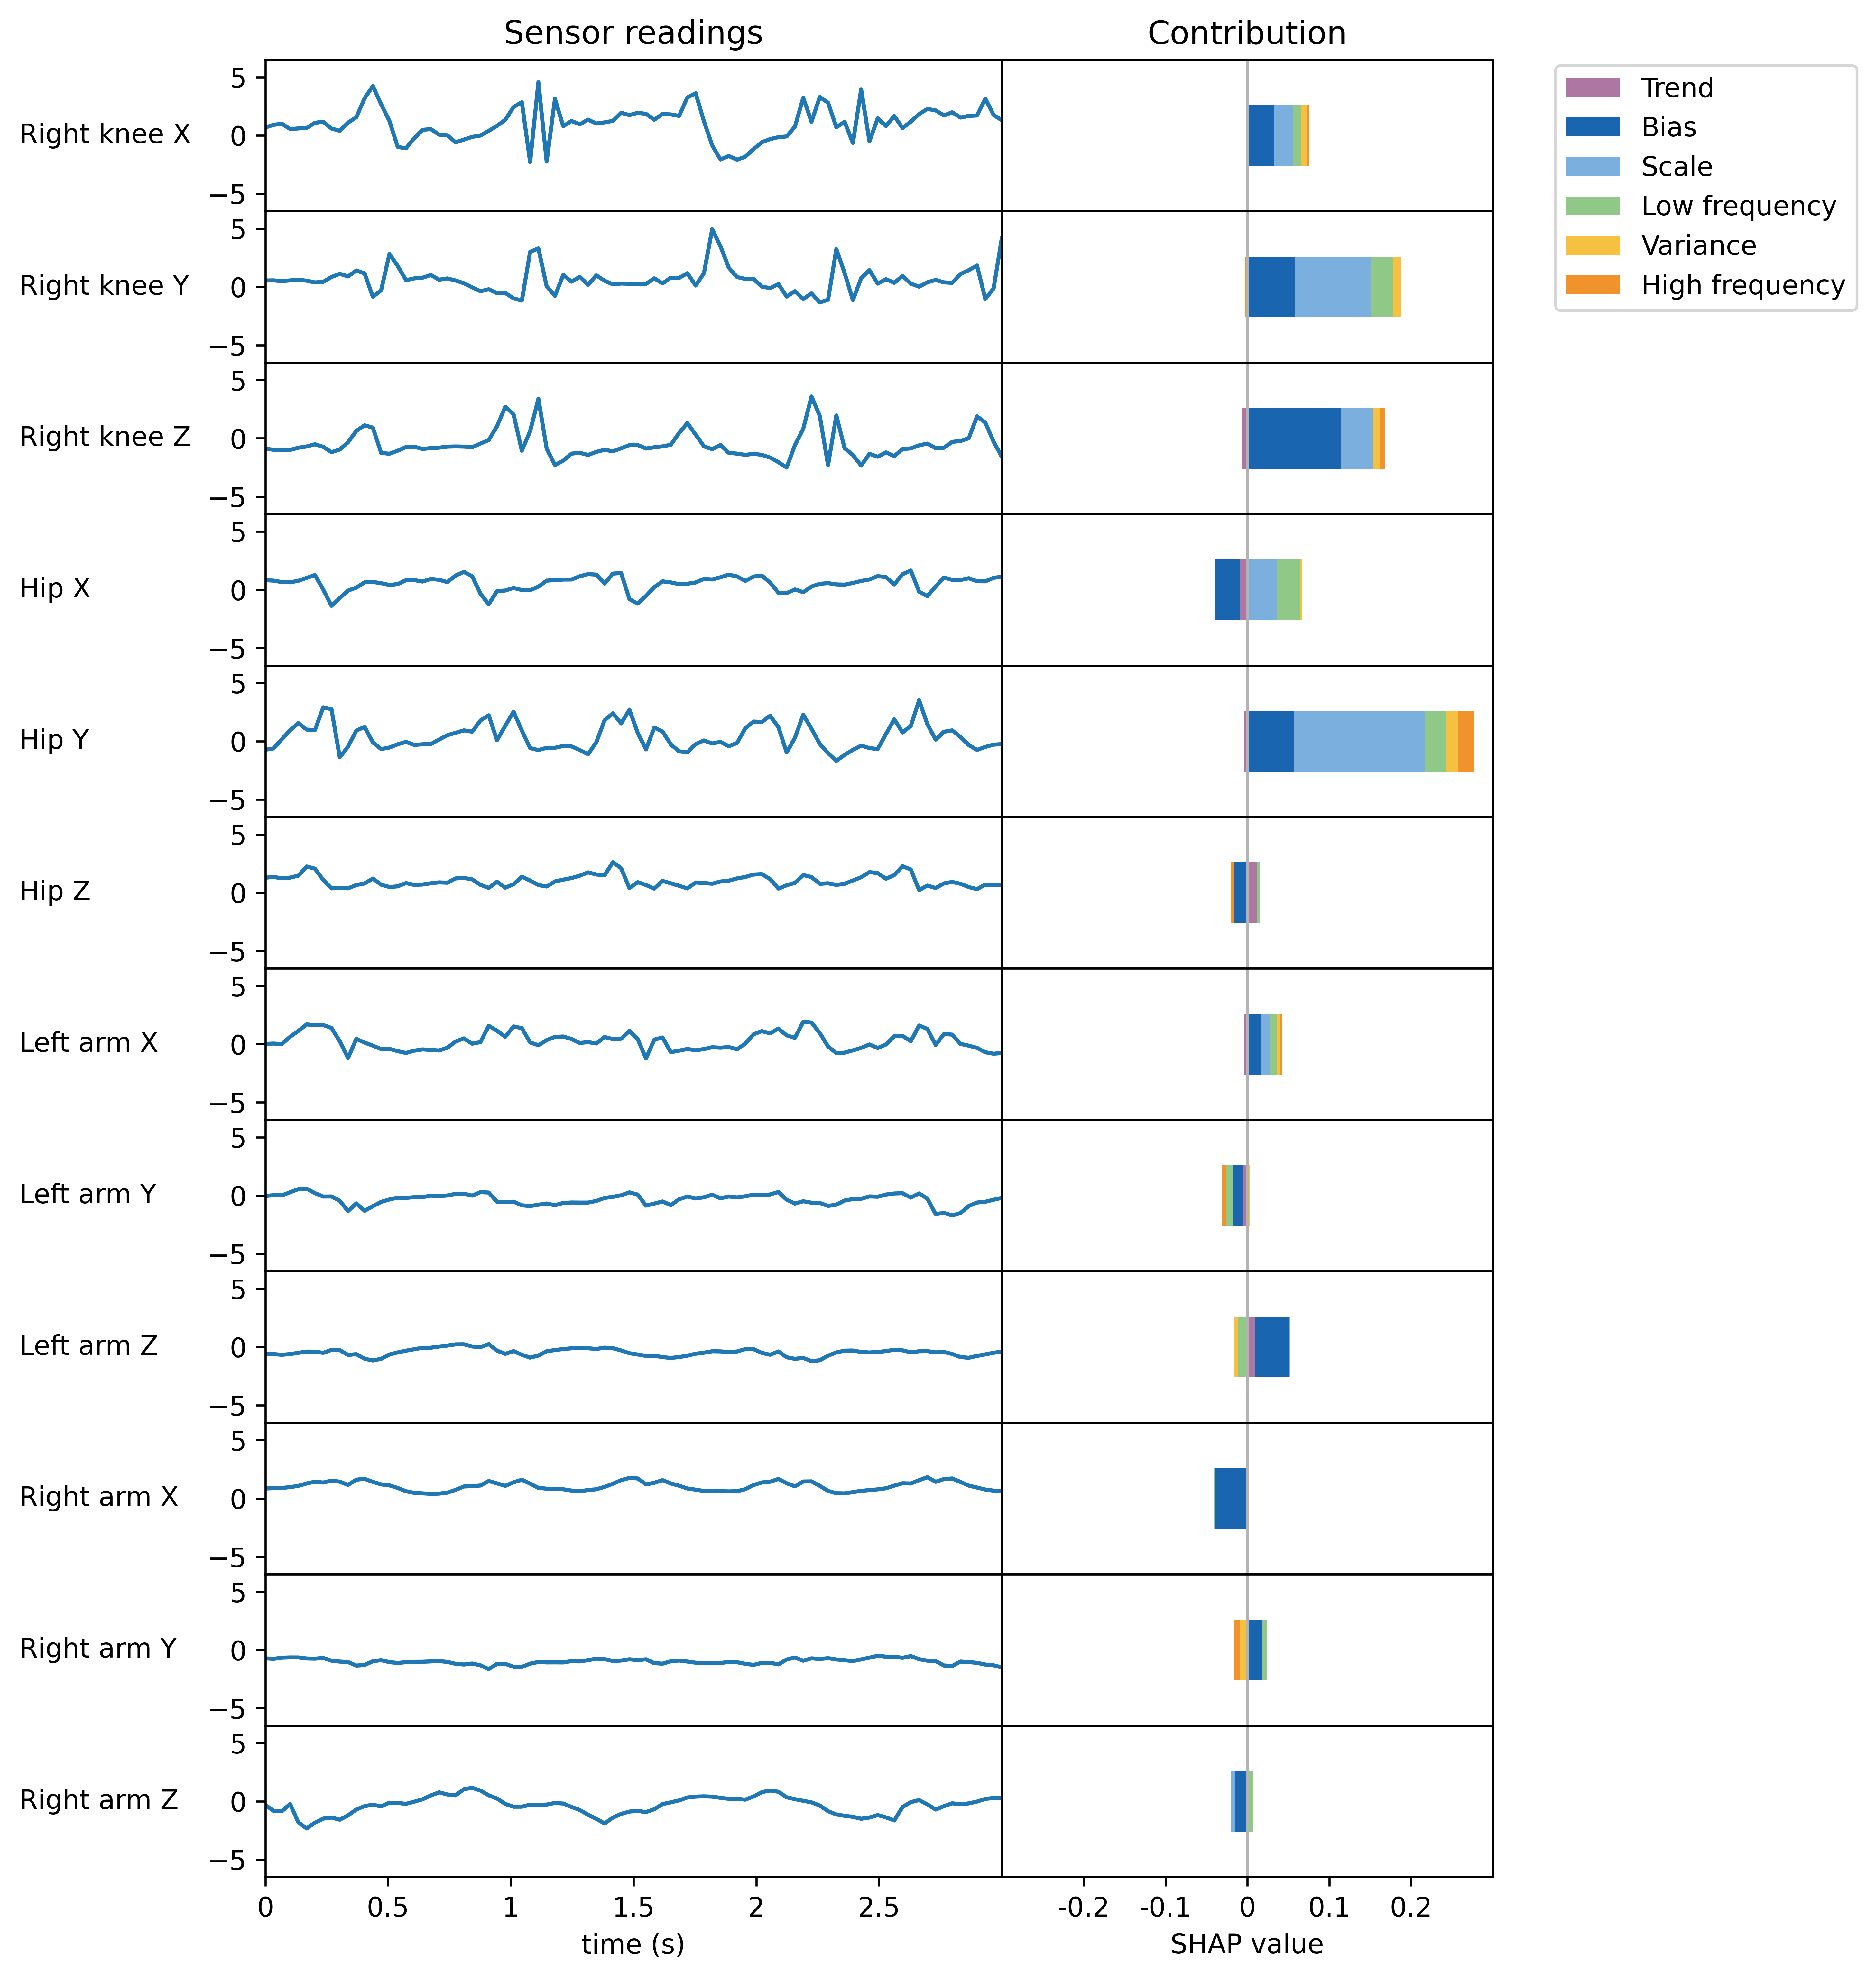

In [ ]:
fig, ax = plt.subplots(len(feature_names), 2, figsize=(8, 10), dpi=600, width_ratios=[0.6, 0.4])
t = np.linspace(0, 3, 90)

# Use tight layout for the figure
fig.tight_layout()

feature_names = ['Right knee X', 'Right knee Y', 'Right knee Z',
                 'Hip X', 'Hip Y', 'Hip Z',
                 'Left arm X', 'Left arm Y', 'Left arm Z',
                 'Right arm X', 'Right arm Y', 'Right arm Z'
                 ]

# Remove space between Axes
fig.subplots_adjust(hspace=0)
fig.subplots_adjust(wspace=0)

for i, name in enumerate(feature_names):
    ax[i, 0].plot(t, X_test[i_select, :, i])
    ax[i, 0].set_ylim(-6.5, 6.5)
    ax[i, 0].set_xlim(0, 3)
    ax[i, 0].set_ylabel(name, rotation=0, labelpad=70,  va='center', ha='left')

    for k in np.arange(0, n_components):
        ax[i, 1].barh(0, s_vals.T[k, i], left=data_stack[k, i], label=component_names[k], color=cmap[k])
        ax[i, 1].set_xlim(-0.3, 0.3)
        ax[i, 1].set_ylim(-1, 1)
        ax[i, 1].set_yticks([])
        ax[i, 1].axvline(x=0, color='#b3b3b3', linewidth=1)

    if i + 1 < len(feature_names):
        ax[i, 0].set_xticks([])
        ax[i, 1].set_xticks([])
    else:
        ax[i, 0].set_xlabel('time (s)')
        ax[i, 0].set_xticks([0, 0.5, 1, 1.5, 2, 2.5], [0, 0.5, 1, 1.5, 2, 2.5])
        ax[i, 1].set_xlabel('SHAP value')
        ax[i, 1].set_xticks([-0.2, -0.1, 0, 0.1, 0.2], [-0.2, -0.1, 0, 0.1, 0.2])
ax[0, 0].set_title('Sensor readings')
ax[0, 1].set_title('Contribution')
ax[0, 1].legend(bbox_to_anchor=(1.1, 1.05))